# Multiple Linear Regression

## Libraries

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn import preprocessing
from sklearn.model_selection import TimeSeriesSplit

In [40]:
df_train = pd.read_csv('data/df_train.csv')
df_train.head()

,Month_sin__Month,Month_cos__Month,Day_sin__Day,Day_cos__Day,Weekday_sin__Weekday,Weekday_cos__Weekday,Time_sin__Time,Time_cos__Time,Spline_month__Month_sp_0,Spline_month__Month_sp_1,...,scaled__NO2,scaled__O3,scaled__PM10,scaled__Hr,scaled__RainDur,scaled__T,scaled__WVv,scaled__StrGlo,scaled__meanVehicles,remainder__Year
0,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,-0.682185,-0.052938,0.431353,-0.128157,-0.345975,-0.436262,1.139169,-0.616970,-0.145770,2018.0
1,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,-1.144052,0.130613,0.194810,-0.307204,-0.345975,-0.363149,-0.109481,-0.616970,-0.563023,2018.0
2,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,-0.940408,0.021671,1.333171,-0.183898,-0.345975,-0.431219,4.146787,-0.616970,-0.862562,2018.0
3,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,-0.277244,-0.136461,0.486264,-0.005414,-0.326709,-0.403487,0.856866,-0.617014,0.885274,2018.0
4,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,-1.182786,0.156033,-0.316290,-0.132098,-0.345975,-0.371973,0.205396,-0.617014,0.028698,2018.0


In [73]:
spline_cols = list(df_train.filter(like="Spline_").columns)
encoded_cols = list(df_train.filter(like="encoded_").columns)
scaled_cols_incl_y = list(df_train.filter(like="scaled_").columns)
scaled_cols = scaled_cols_incl_y[3:] # remove all pollutants
tri_cols = list(df_train.iloc[:,0:8].columns)

In [74]:
df_test = pd.read_csv('data/df_test.csv')
df_test.head()

,Month_sin__Month,Month_cos__Month,Day_sin__Day,Day_cos__Day,Weekday_sin__Weekday,Weekday_cos__Weekday,Time_sin__Time,Time_cos__Time,Spline_month__Month_sp_0,Spline_month__Month_sp_1,...,scaled__NO2,scaled__O3,scaled__PM10,scaled__Hr,scaled__RainDur,scaled__T,scaled__WVv,scaled__StrGlo,scaled__meanVehicles,remainder__Year
0,-2.449294e-16,1.000000,0.433884,-0.900969,0.781831,0.623490,-0.258819,0.965926,0.166667,0.666667,...,1.015045,-1.442453,4.803164,1.511980,-0.345975,-1.732123,-0.250633,-0.61697,0.000320,2025.0
1,-2.449294e-16,1.000000,0.433884,-0.900969,0.781831,0.623490,-0.258819,0.965926,0.166667,0.666667,...,1.043802,-1.415052,16.632400,1.708481,-0.345975,-1.638841,-0.446074,-0.61697,-0.297116,2025.0
2,-2.449294e-16,1.000000,0.433884,-0.900969,0.781831,0.623490,-0.258819,0.965926,0.166667,0.666667,...,0.942273,-1.441793,9.380895,1.687648,-0.345975,-1.709433,0.042529,-0.61697,-0.825776,2025.0
3,5.000000e-01,0.866025,0.781831,0.623490,0.974928,-0.222521,0.000000,1.000000,0.033083,0.529225,...,1.017393,-1.454668,7.475883,1.393741,-0.345975,-1.744728,-0.511221,-0.61697,0.986171,2025.0
4,5.000000e-01,0.866025,0.781831,0.623490,0.974928,-0.222521,0.000000,1.000000,0.033083,0.529225,...,1.156481,-1.429248,29.406749,1.708481,-0.345975,-1.642623,-0.348353,-0.61697,0.140105,2025.0


Error in callback <function _draw_all_if_interactive at 0x0000020E8D34C5E0> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

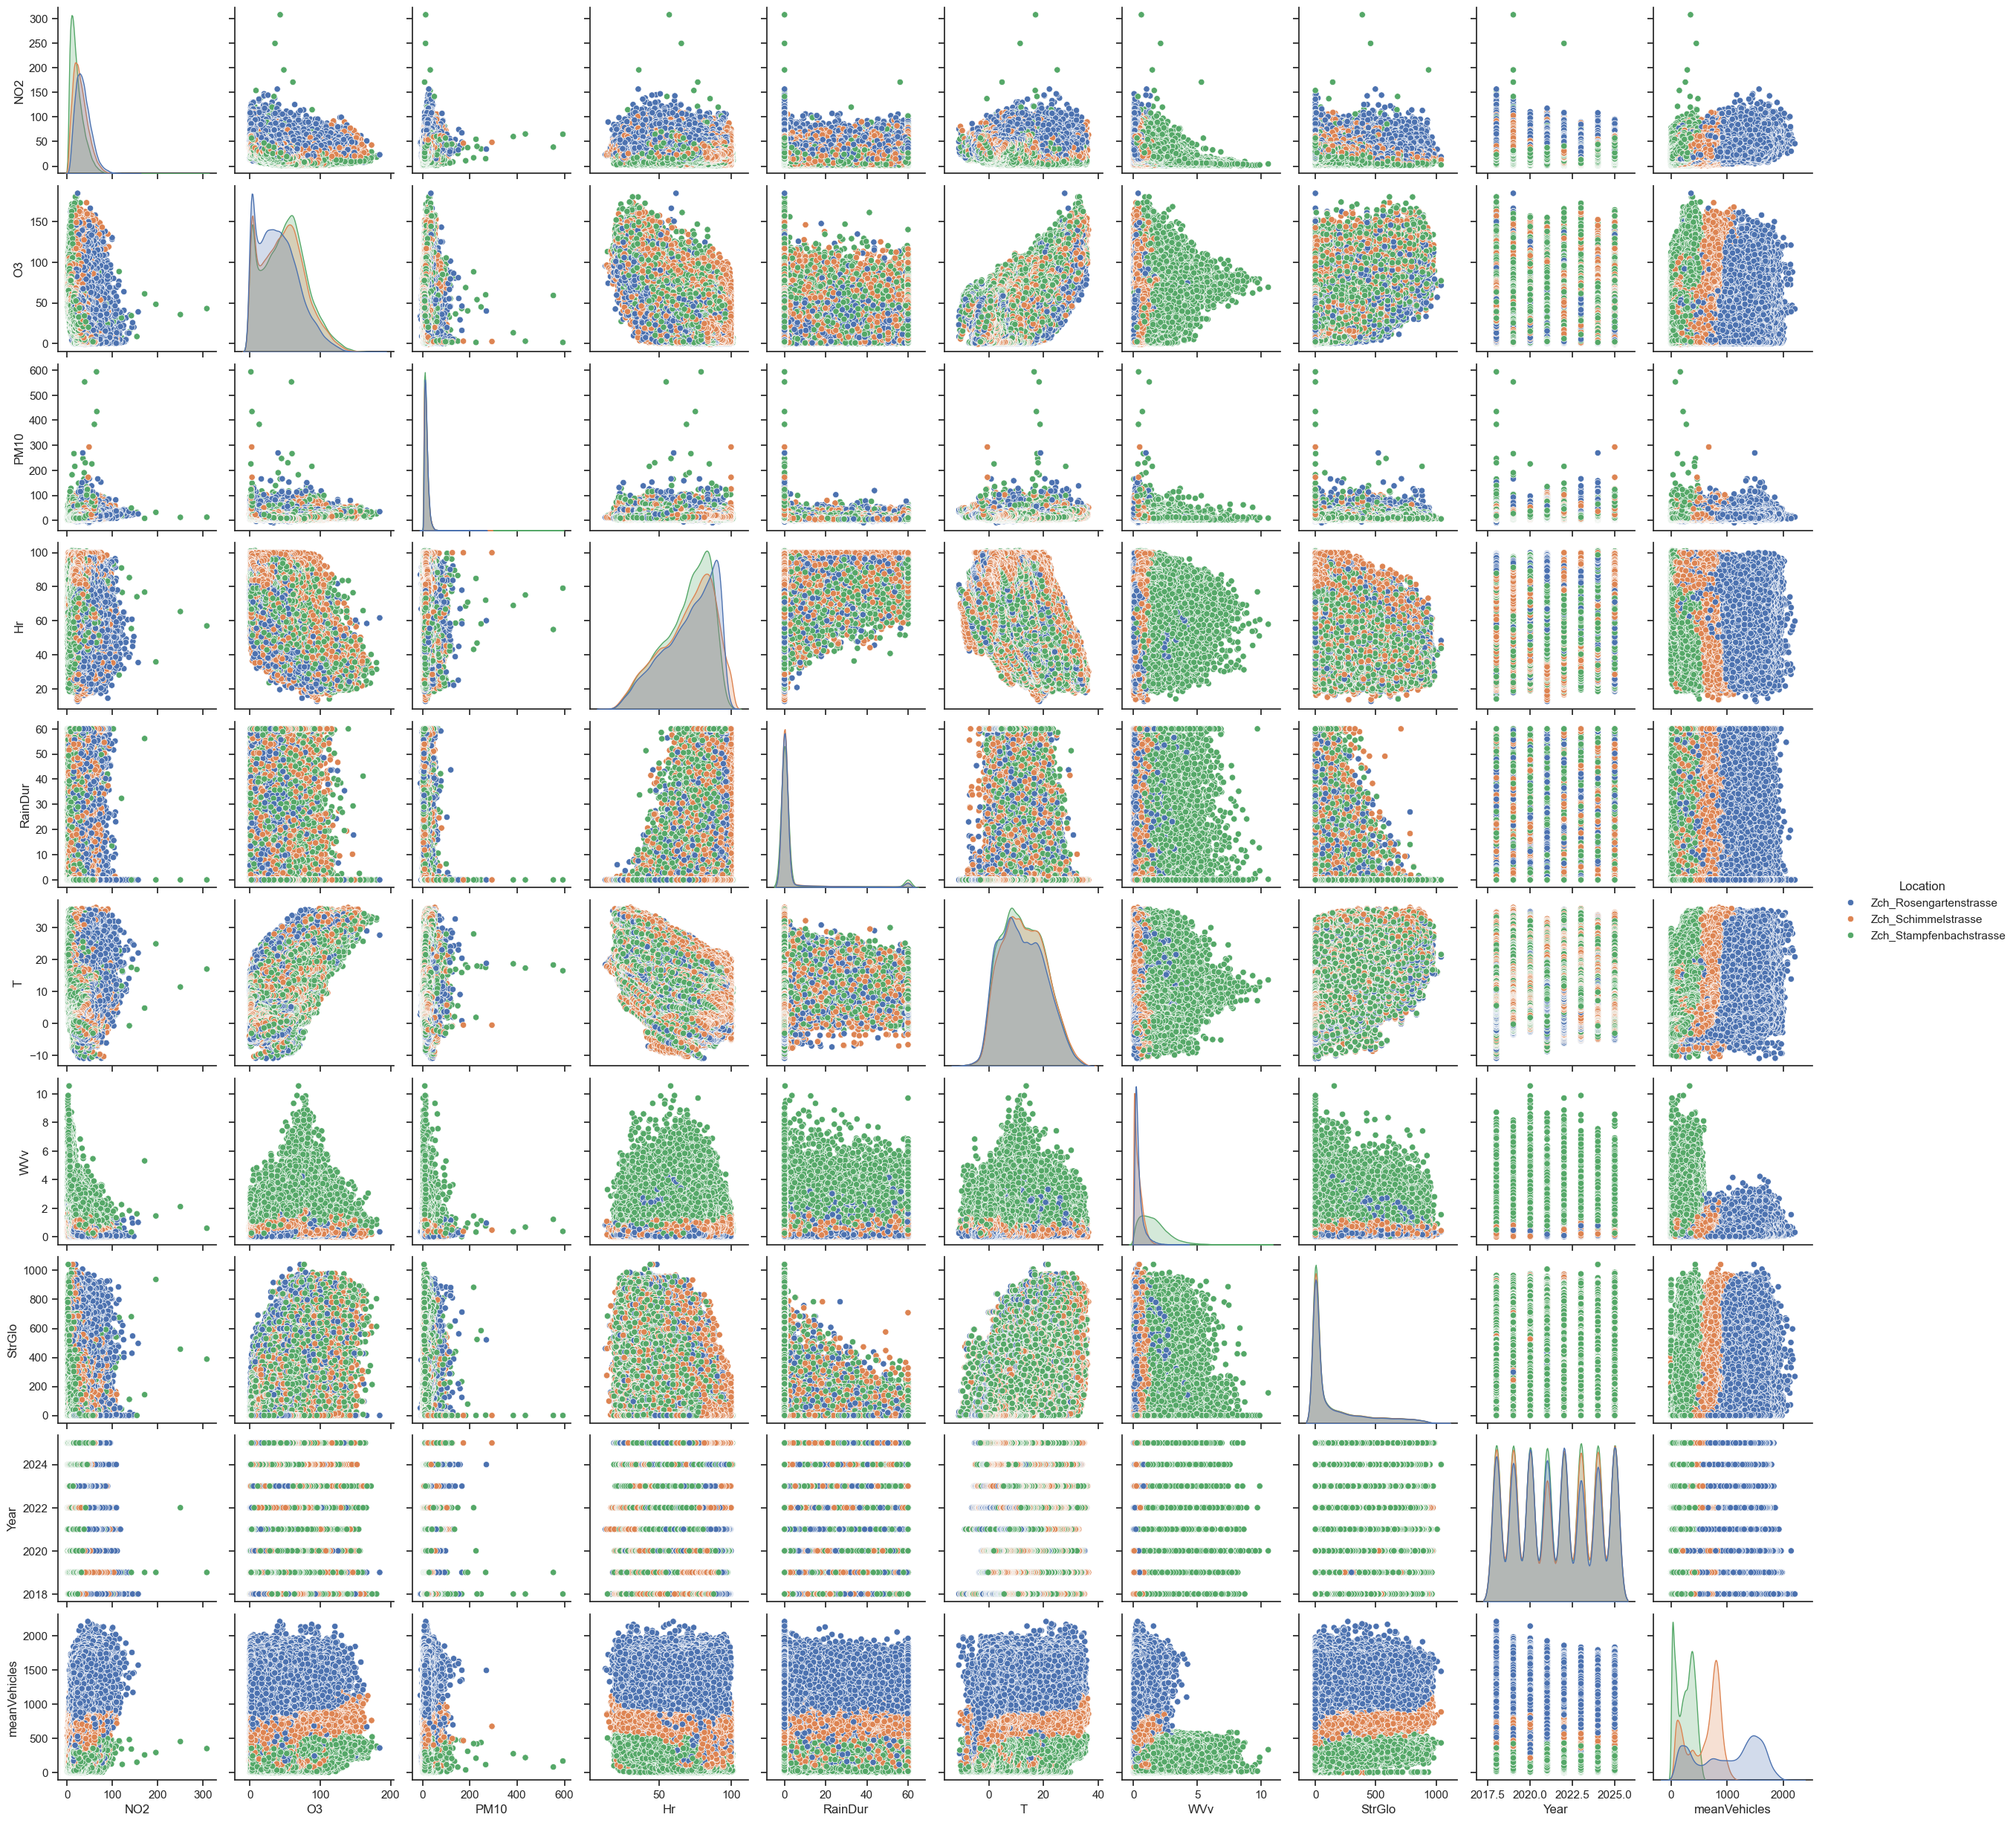

In [8]:
# plotting a pairplot
# df_pairplot = df.drop(columns=["Datetime", "Month", "Weekday", "YearMonth"])
#
# sns.set_theme(style="ticks")
#
# sns.pairplot(df_pairplot, hue="Location")

In [17]:
# df[["Month", "Weekday", "Year"]] = df[["Month", "Weekday", "Year"]].astype("category")
#
# df.dtypes

## Time-based cross-validation

In [64]:
# fixed training set size
tss = TimeSeriesSplit(n_splits=5,gap=24*2,max_train_size=24 * 365,test_size=24*30)

In [65]:
# building linear regression model
model_lr = LinearRegression()

In [66]:
# model evaluation
def evaluate(model, X, y):
    ret = cross_validate(model, X, y, cv=tss, scoring=["neg_root_mean_squared_error"])
    rmse = -ret["test_neg_root_mean_squared_error"]
    print("%.2f ± %.2f" % (rmse.mean(), rmse.std()))

In [67]:
X_tri = df_train[encoded_cols + tri_cols + scaled_cols]
X_spl = df_train[spline_cols + tri_cols + scaled_cols]

y_NO2 = df_train["scaled__NO2"]
y_O3 = df_train["scaled__O3"]
y_PM10 = df_train["scaled__PM10"]

In [75]:
df_train[list(scaled_cols_incl_y[0:3])].describe()

,scaled__NO2,scaled__O3,scaled__PM10
count,171398.000000,171398.000000,171398.000000
mean,0.044709,0.001742,0.016066
std,1.019666,0.997718,1.015832
min,-1.649935,-1.523665,-2.595124
25%,-0.744393,-0.811576,-0.655264
50%,-0.127592,-0.032140,-0.190627
75%,0.658815,0.667074,0.432409
max,16.391059,4.578776,61.111887


In [71]:
print("linear regression, trigonometric encoding, NO2")
evaluate(model_lr, X_tri, y_NO2)

print("linear regression, spline encoding, NO2")
evaluate(model_lr, X_spl, y_NO2)

print("linear regression, trigonometric encoding, O3")
evaluate(model_lr, X_tri, y_O3)

print("linear regression, spline encoding, O3")
evaluate(model_lr, X_spl, y_O3)

print("linear regression, trigonometric encoding, PM10")
evaluate(model_lr, X_tri, y_PM10)

print("linear regression, spline encoding, PM10")
evaluate(model_lr, X_spl, y_PM10)

linear regression, trigonometric encoding, NO2
0.65 ± 0.20
linear regression, spline encoding, NO2
0.71 ± 0.23
linear regression, trigonometric encoding, O3
0.63 ± 0.11
linear regression, spline encoding, O3
1.33 ± 1.36
linear regression, trigonometric encoding, PM10
0.71 ± 0.15
linear regression, spline encoding, PM10
1.24 ± 1.11


In [78]:
# fitting the model
model_lr.fit(X_tri, y_NO2)

LinearRegression()

In [82]:
X_tri_test = df_test[encoded_cols + tri_cols + scaled_cols]
X_spl_test = df_test[spline_cols + tri_cols + scaled_cols]

y_NO2_test = df_test["scaled__NO2"]

In [81]:
predictions = model_lr.predict(X_tri_test)

array([0.43006251, 0.42943437, 0.42188848, ..., 1.00664533, 0.75218998,
       0.97707235])

In [84]:
# model evaluation
print('mean_squared_error:', mean_squared_error(y_NO2_test, predictions))
print('mean_absolute_error:', mean_absolute_error(y_NO2_test, predictions))

mean_squared_error: 0.49926876698360245
mean_absolute_error: 0.580408660224262
